In [7]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree


data = {
    "Outlook": [
        "Sunny", "Sunny", "Overcast", "Rain", "Rain", "Rain",
        "Overcast", "Sunny", "Sunny", "Rain", "Sunny",
        "Overcast", "Overcast", "Rain"
    ],
    "Temperature": [
        "Hot", "Hot", "Hot", "Mild", "Cool", "Cool",
        "Cool", "Mild", "Cool", "Mild", "Mild",
        "Mild", "Hot", "Mild"
    ],
    "Humidity": [
        "High", "High", "High", "High", "Normal", "Normal",
        "Normal", "High", "Normal", "Normal", "Normal",
        "High", "Normal", "High"
    ],
    "Wind": [
        "Weak", "Strong", "Weak", "Weak", "Weak", "Strong",
        "Strong", "Weak", "Weak", "Weak", "Strong",
        "Strong", "Weak", "Strong"
    ],
    "PlayTennis": [
        "No", "No", "Yes", "Yes", "Yes", "No",
        "Yes", "No", "Yes", "Yes", "Yes",
        "Yes", "Yes", "No"
    ]
}



In [ ]:
df = pd.DataFrame(data)
df_encoded = df.copy()

for column in df_encoded.columns:
    le = LabelEncoder()
    df_encoded[column] = le.fit_transform(df_encoded[column])

X = df_encoded.drop("PlayTennis", axis=1)
y = df_encoded["PlayTennis"]

full_tree = DecisionTreeClassifier(random_state=42)

full_tree.fit(X, y)

print("Tree Depth:", full_tree.get_depth())
print("Number of Leaves:", full_tree.get_n_leaves())
print("Training Accuracy:", full_tree.score(X, y))

Tree Depth: 4
Number of Leaves: 7
Training Accuracy: 1.0


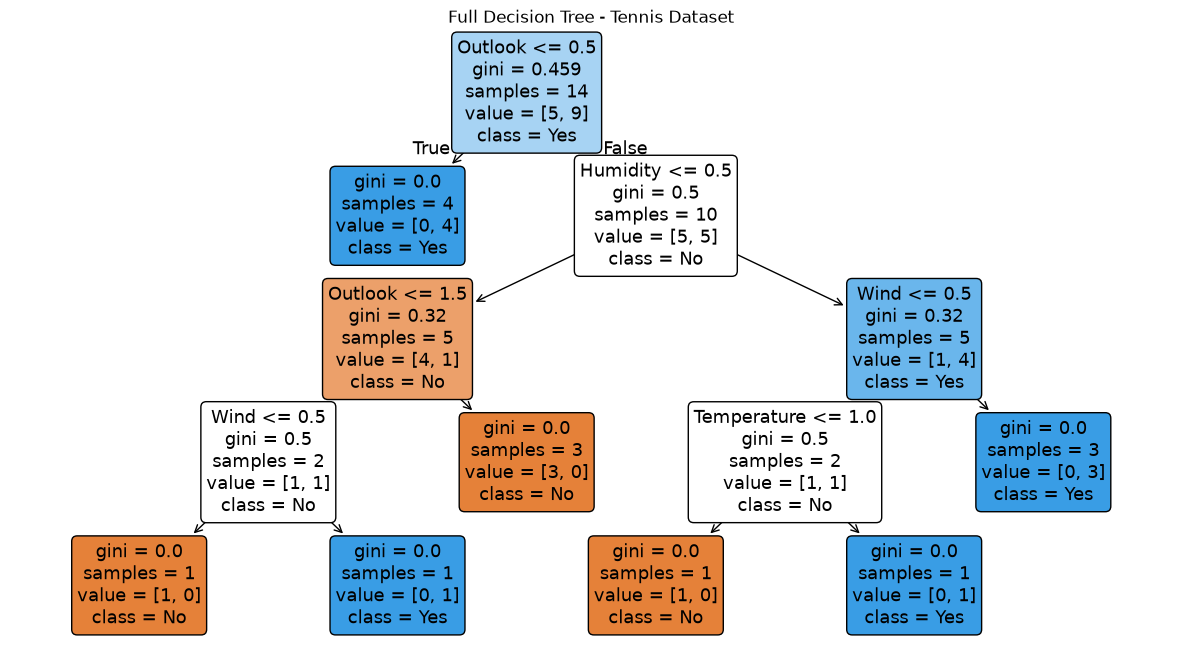

In [5]:
plt.figure(figsize=(15, 8))

plot_tree(
    full_tree,
    feature_names=X.columns,
    class_names=["No", "Yes"],
    filled=True,
    rounded=True
)

plt.title("Full Decision Tree - Tennis Dataset")
plt.show()

Pre-Pruned Tree
Tree Depth: 2
Number of Leaves: 3
Training Accuracy: 0.8571428571428571


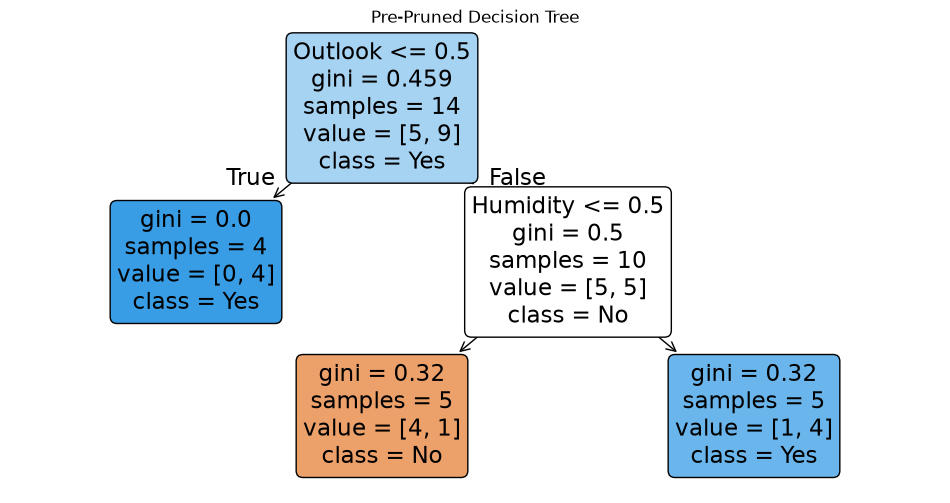

In [9]:
pruned_tree = DecisionTreeClassifier(
    max_depth=2,
    random_state=42
)

pruned_tree.fit(X, y)

print("Pre-Pruned Tree")
print("Tree Depth:", pruned_tree.get_depth())
print("Number of Leaves:", pruned_tree.get_n_leaves())
print("Training Accuracy:", pruned_tree.score(X, y))

plt.figure(figsize=(12, 6))

plot_tree(
    pruned_tree,
    feature_names=X.columns,
    class_names=["No", "Yes"],
    filled=True,
    rounded=True
)

plt.title("Pre-Pruned Decision Tree")
plt.show()


In [15]:
path = full_tree.cost_complexity_pruning_path(X, y)
 
ccp_alphas = path.ccp_alphas
 
print(ccp_alphas)

[0.         0.05714286 0.05714286 0.11530612]


In [7]:
post_pruned_tree = DecisionTreeClassifier(
    ccp_alpha=ccp_alphas[1],
    random_state=42
)

post_pruned_tree.fit(X, y)

print("Tree Depth:", post_pruned_tree.get_depth())
print("Number of Leaves:", post_pruned_tree.get_n_leaves())
print("Training Accuracy:", post_pruned_tree.score(X, y))

Tree Depth: 2
Number of Leaves: 3
Training Accuracy: 0.8571428571428571


In [9]:
models = {
    "Full Tree": full_tree,
    "Pre-Pruned Tree": pruned_tree,
    "Post-Pruned Tree": post_pruned_tree
}

for name, model in models.items():
    print(f"\n{name}")
    print("-" * 30)
    print("Depth:", model.get_depth())
    print("Leaves:", model.get_n_leaves())
    print("Training Accuracy:", round(model.score(X, y), 2))


Full Tree
------------------------------
Depth: 4
Leaves: 7
Training Accuracy: 1.0

Pre-Pruned Tree
------------------------------
Depth: 2
Leaves: 3
Training Accuracy: 0.86

Post-Pruned Tree
------------------------------
Depth: 2
Leaves: 3
Training Accuracy: 0.86
